# Indicateur d'éloignement aux services

*Choix méthodologiques, pondération et formule finale — BPE 2025, France métropolitaine*

À lancer après `src/indicateur.py` (qui produit `data/processed/indicateur_communes.csv`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

# Rendre src/indicateur.py importable, que le notebook soit lancé depuis la racine ou depuis src/
for d in (Path.cwd(), Path.cwd() / "src", Path.cwd().parent / "src"):
    if (d / "indicateur.py").exists():
        sys.path.insert(0, str(d))
        break
from indicateur import PANIER, PROCESSED, table_poids

# Couleurs : un bleu pour les grandeurs, un orange pour comparer, encres neutres
BLEU, ORANGE = "#2a78d6", "#eb6834"
ENCRE, ENCRE_2, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"
SEQUENTIEL = LinearSegmentedColormap.from_list("bleus", ["#eef3fb", "#9cc0ee", BLEU, "#0d3a73"])

plt.rcParams.update({
    "font.size": 9, "axes.edgecolor": GRILLE,
    "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlecolor": ENCRE, "axes.titlelocation": "left",
})


def fr(x: float, dec: int = 1) -> str:
    """Nombre au format français (virgule décimale, espace des milliers)."""
    return f"{x:,.{dec}f}".replace(",", " ").replace(".", ",")


def tableau(df: pd.DataFrame):
    """Affiche un DataFrame sans index, aligné à gauche pour le texte."""
    return df.style.hide(axis="index").set_properties(**{"text-align": "left"})

## Chargement des résultats

In [2]:
poids = table_poids()
f = pd.read_csv(PROCESSED / "indicateur_communes.csv", dtype={"DEPCOM": str, "DEP": str})
services = list(PANIER)
n = len(f)

# Statistiques par service
stats = pd.DataFrame({
    "part_communes": (f[services] == 0).mean(),
    "part_pop": f[services].eq(0).mul(f["population"], axis=0).sum() / f["population"].sum(),
    "d_moy": f[services].mean(),
    "d_max": f[services].max(),
})
stats["contribution"] = poids["poids"] * stats["d_moy"]
stats["contribution"] /= stats["contribution"].sum()

# Chiffres repris dans le texte
moy_pop = np.average(f["indicateur"], weights=f["population"])
rho = f[["indicateur", "indic_poids_egaux", "indic_normalise"]].corr("spearman")
rho_dens = f[["indicateur", "densite"]].corr("spearman").iloc[0, 1]
dep = f.groupby("DEP").apply(lambda g: np.average(g["indicateur"], weights=g["population"]))
q = f["indicateur"].quantile([0.1, 0.5, 0.9])
part_0_ou_1 = (f["nb_services_absents"] >= 18).mean()
part_rares = stats.loc[["urgences", "maternite"], "contribution"].sum()
poids_rares = poids.loc[["urgences", "maternite"], "poids"].sum()
nb_mairie = (f["source_centre"] == "mairie").sum()

## En bref

Pour chaque commune et chacun des 19 services d'un panier de la vie courante, on mesure la
distance à parcourir pour y accéder : **0 km si la commune possède le service**, sinon la
distance à vol d'oiseau entre le centre de la commune et l'équipement le plus proche. Les 19
distances sont résumées par leur **moyenne pondérée**, les poids traduisant l'importance de
chaque service. L'indicateur s'exprime donc en kilomètres : c'est la distance moyenne à
parcourir pour atteindre un service, quand on accorde plus de place aux services essentiels.

$$I_c \;=\; \sum_{s=1}^{19} w_s \, d_{c,s} \qquad \text{avec}\quad \sum_{s} w_s = 1$$

Sur les 34 788 communes et arrondissements municipaux de métropole, l'indicateur médian vaut **5,5 km** (10 % des communes sous 2,1 km, 10 % au-dessus de 8,9 km). Pondéré par la population, il tombe à **1,9 km** : la plupart des habitants vivent près des services, mais une majorité de communes, petites et rurales, en sont éloignées.

## 1. Données et champ

- **Base permanente des équipements (BPE) 2025, INSEE** : 2,9 millions d'équipements,
  235 types (code TYPEQU), avec la commune d'implantation et les coordonnées.
- **Liste des communes, geo.api.gouv.fr** : code, nom, population, surface et centre
  géographique de chaque commune (sert pour les communes sans mairie géolocalisée et pour la densité).
- **Champ : France métropolitaine, Corse incluse** (équipements en Lambert 93, EPSG 2154).
  Les DROM sont exclus : leurs distances ne sont pas comparables (îles, relief) et ils ont
  leur propre système de coordonnées.
- **Paris, Lyon et Marseille sont découpées en arrondissements**, car la BPE les code ainsi.

Au total : **34 788 unités géographiques** (appelées « communes » ensuite).

## 2. Le « centre de la ville »

La distance part d'un point représentant la commune. Deux candidats : le centre géométrique du
territoire communal, ou la mairie. **Nous retenons la mairie** (type A129 de la BPE), comme le
fait l'INSEE pour son distancier Métric : elle se trouve au chef-lieu, cœur historique du bourg
où vit l'essentiel de la population. Le centre géométrique peut tomber au milieu d'une forêt ou
d'une montagne dans les grandes communes rurales.

- Mairie retenue si sa géolocalisation est bonne ou acceptable (qualité A ou B) : **32 215 communes** (92,6 %).
- Sinon (mairie absente ou mal placée, arrondissements municipaux) : centre géographique de geo.api.gouv.fr (2 573 communes).
- Commune nouvelle avec plusieurs mairies (mairies annexes) : celle la plus proche du centre géographique.

## 3. Le panier de 19 services

La BPE compte 235 types d'équipements, dont beaucoup ne relèvent pas des besoins courants
(maçon, golf, tribunal de commerce...). Nous retenons **19 services de la vie courante**, qui
couvrent les grands besoins : se nourrir, se soigner, scolariser ses enfants, faire ses
démarches, se déplacer, se cultiver. Le panier mêle des services de proximité (boulangerie,
école), intermédiaires (collège, banque) et supérieurs (lycée, urgences, maternité), à l'image
des gammes d'équipements de l'INSEE.

Quand plusieurs codes TYPEQU rendent le même service, ils sont **regroupés** : la commune
possède le service dès qu'elle a au moins l'un d'eux. Par exemple, un supermarché, une
supérette ou une épicerie permettent tous de faire ses courses ; une agence postale communale
rend les mêmes services courants qu'un bureau de poste.

## 4. Distance de la commune à chaque service

Pour la commune $c$ et le service $s$ :

$$d_{c,s} \;=\; \mathbf{1}\left[\,n_{c,s}=0\,\right]\;\times\;\min_{e\,\in\,\mathcal{E}_s}\ \delta(x_c,\,x_e)$$

- $n_{c,s}$ est le nombre d'équipements du service $s$ implantés dans la commune $c$ ;
  l'indicatrice vaut 1 si la commune n'en a aucun. **Si la commune possède le service, la
  distance vaut 0**, quelle que soit la taille de la commune.
- $\mathcal{E}_s$ est l'ensemble des équipements du service $s$ géolocalisés en métropole,
  $x_c$ le centre de la commune, $x_e$ la position de l'équipement.
- $\delta$ est la distance du grand cercle (formule de haversine, rayon terrestre
  $R = 6\,371$ km), en kilomètres :

$$\delta = 2R\,\arcsin\sqrt{\sin^2\frac{\varphi_e-\varphi_c}{2}+\cos\varphi_c\cos\varphi_e\,\sin^2\frac{\lambda_e-\lambda_c}{2}}$$

La présence se lit sur le code commune de la BPE : un équipement sans coordonnées (4 % des
lignes) compte pour la présence, mais ne sert pas de destination. Le plus proche voisin est
trouvé avec un arbre de recherche (BallTree, scikit-learn), ce qui traite les 35 000 communes
× 19 services en moins d'une minute.

## 5. Pondération : l'importance des services

Tous les services ne se valent pas : être loin d'un commerce alimentaire pèse plus sur la vie
quotidienne qu'être loin d'une bibliothèque. Plutôt que de fixer des poids « à l'œil », chaque
service est noté sur **trois critères explicites**, ce qui rend le choix transparent et
discutable critère par critère :

- **E - Essentialité** : 2 = vital ou obligatoire (santé, alimentation, scolarité
  obligatoire), 1 = important pour la vie courante, 0 = confort ou loisir.
- **F - Fréquence de recours** : 2 = quotidien ou hebdomadaire, 1 = de mensuel à quelques
  fois par an, 0 = rare ou exceptionnel.
- **P - Public concerné** : 1 = presque toute la population, 0 = un public particulier
  (enfants, parents, femmes enceintes, malades chroniques).

$$\text{score}_s = 1 + E_s + F_s + P_s \in [1,6] \qquad w_s = \frac{\text{score}_s}{\sum_{k=1}^{19}\text{score}_k}$$

Le « 1 + » garantit qu'aucun service n'a un poids nul : tous ont été jugés assez utiles pour entrer dans le panier. La somme des scores vaut 74. L'écart entre le service le plus important (score 6) et le moins important (score 2) est d'un facteur 3 : la pondération hiérarchise sans écraser les services secondaires.

In [6]:
t = poids.sort_values("score", ascending=False)
tableau(pd.DataFrame({
    "Service": t["libelle"],
    "Codes TYPEQU": t["codes"].map(", ".join),
    "E": t["E"], "F": t["F"], "P": t["P"], "Score": t["score"],
    "Poids": (100 * t["poids"]).map(lambda v: f"{fr(v)} %"),
    "Justification": t["raison"],
}))

Service,Codes TYPEQU,E,F,P,Score,Poids,Justification
Commerce alimentaire général,"B104, B105, B201, B202",2,2,1,6,"8,1 %","Hypermarché, supermarché, supérette ou épicerie : se nourrir, plusieurs fois par semaine, pour tous."
Pharmacie,D307,2,1,1,5,"6,8 %","Seul accès aux médicaments ; recours régulier, surtout des personnes âgées."
École maternelle ou élémentaire,"C107, C108, C109",2,2,0,5,"6,8 %","Instruction obligatoire dès 3 ans, trajet quotidien, mais concerne seulement les familles avec jeunes enfants."
Collège,C201,2,2,0,5,"6,8 %","Scolarité obligatoire jusqu'à 16 ans, trajet quotidien, public : 11-15 ans."
Boulangerie-pâtisserie,B207,1,2,1,5,"6,8 %",Commerce de proximité le plus fréquenté ; substituable en partie par le commerce alimentaire général.
Médecin généraliste,D265,2,1,1,5,"6,8 %","Porte d'entrée du système de soins (médecin traitant), recours plusieurs fois par an pour toute la population."
Station-service,B316,1,1,1,4,"5,4 %",Indispensable là où la voiture est le seul moyen de transport.
Crèche ou micro-crèche,"D502, D509",1,2,0,4,"5,4 %","Condition de l'emploi des parents, trajet quotidien, public : 0-3 ans."
"Lycée (général, techno. ou pro.)","C301, C302, C303",1,2,0,4,"5,4 %","Formation obligatoire jusqu'à 18 ans, trajet quotidien, public : 15-18 ans."
"Bureau, agence ou relais de poste","A206, A207, A208",1,1,1,4,"5,4 %","Courrier, colis, services bancaires de base ; recours mensuel."


## 6. L'indicateur final

$$I_c \;=\; \sum_{s=1}^{19} w_s\, d_{c,s} \;=\; \frac{\sum_s (1+E_s+F_s+P_s)\; d_{c,s}}{\sum_s (1+E_s+F_s+P_s)}$$

- **Unité : le kilomètre.** $I_c$ est une moyenne pondérée de distances : « en moyenne, un habitant de $c$ doit parcourir $I_c$ km (à vol d'oiseau) pour atteindre un service, les services essentiels comptant davantage ».
- **$I_c = 0$** si et seulement si la commune possède les 19 services (199 communes). Plus $I_c$ est grand, plus la commune est éloignée des services.
- **Additivité** : on peut décomposer $I_c$ service par service ($w_s\,d_{c,s}$) et dire quel manque pèse le plus pour une commune donnée.

## 7. Résultats

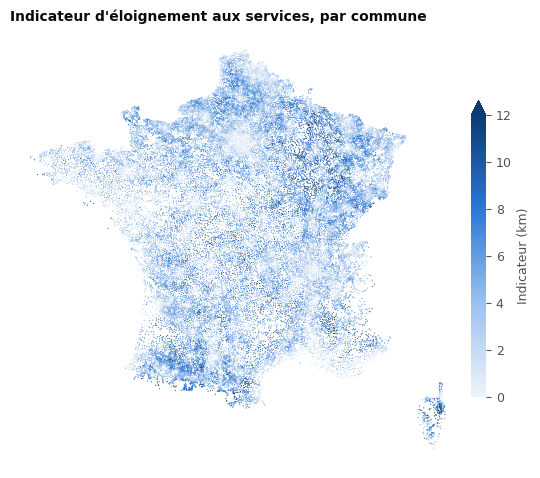

In [8]:
# Carte en points : chaque commune placée à son centre, colorée par l'indicateur
g = f.sort_values("indicateur")
fig, ax = plt.subplots(figsize=(7, 7))
lat_moy = np.radians(46.5)
pts = ax.scatter(g["lon"] * np.cos(lat_moy), g["lat"], c=g["indicateur"], s=0.6,
                 cmap=SEQUENTIEL, vmin=0, vmax=12, linewidths=0, rasterized=True)
ax.set_aspect("equal")
ax.axis("off")
barre = fig.colorbar(pts, ax=ax, shrink=0.55, pad=0.01, extend="max")
barre.set_label("Indicateur (km)")
barre.outline.set_visible(False)
ax.set_title("Indicateur d'éloignement aux services, par commune")
plt.show()

Les communes les plus éloignées des services se concentrent dans les espaces ruraux à petites
communes : Champagne et plateaux lorrains, Gers et Landes, Préalpes du Sud (Drôme,
Hautes-Alpes), Massif central et intérieur de la Corse. Les agglomérations et leurs couronnes,
ainsi que l'ouest de la France aux communes plus vastes, apparaissent en clair.

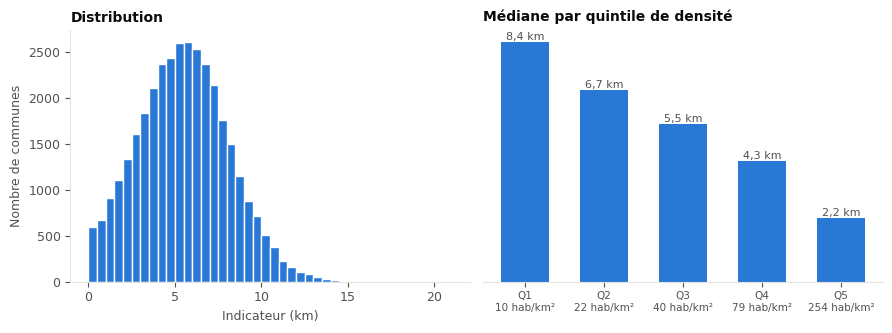

In [9]:
# Histogramme de l'indicateur + indicateur médian par quintile de densité
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
a1.hist(f["indicateur"], bins=np.arange(0, 21.5, 0.5), color=BLEU, edgecolor="white", lw=0.5)
a1.set_xlabel("Indicateur (km)")
a1.set_ylabel("Nombre de communes")
a1.set_title("Distribution")

quintile = pd.qcut(f["densite"].rank(method="first"), 5, labels=False)
qd = f.groupby(quintile).agg(dens=("densite", "median"), ind=("indicateur", "median"))
etiquettes = [f"Q{i + 1}\n{d:.0f} hab/km²" for i, d in enumerate(qd["dens"])]
barres = a2.bar(etiquettes, qd["ind"], color=BLEU, width=0.6)
a2.bar_label(barres, labels=[f"{fr(v)} km" for v in qd["ind"]], fontsize=8, color=ENCRE_2)
a2.set_title("Médiane par quintile de densité")
a2.set_yticks([])
a2.spines["left"].set_visible(False)
a2.tick_params(axis="x", labelsize=7.5)
fig.tight_layout()
plt.show()

La corrélation de rang (Spearman) entre l'indicateur et la densité vaut **-0,85** : plus une commune est dense, plus elle est proche des services. Par département (moyenne pondérée par la population), l'indicateur va de 0,11 km à Paris à 5,3 km dans le département le plus éloigné (code 32). Les cinq départements les plus éloignés : 32, 23, 48, 55, 36.

### Situation de chaque service

In [10]:
t = stats.sort_values("d_moy")
display(tableau(pd.DataFrame({
    "Service": [PANIER[k]["libelle"] for k in t.index],
    "Communes équipées": (100 * t["part_communes"]).map(lambda v: f"{fr(v)} %"),
    "Population couverte": (100 * t["part_pop"]).map(lambda v: f"{fr(v)} %"),
    "Distance moy.": t["d_moy"].map(lambda v: f"{fr(v)} km"),
    "Distance max.": t["d_max"].map(lambda v: f"{fr(v)} km"),
})))

Service,Communes équipées,Population couverte,Distance moy.,Distance max.
École maternelle ou élémentaire,"61,0 %","95,8 %","1,3 km","13,9 km"
"Bureau, agence ou relais de poste","39,7 %","87,4 %","2,1 km","12,1 km"
Bibliothèque,"39,8 %","83,3 %","2,4 km","31,6 km"
Boulangerie-pâtisserie,"36,3 %","87,4 %","2,5 km","21,2 km"
Infirmier,"33,6 %","86,8 %","2,7 km","21,8 km"
Commerce alimentaire général,"30,2 %","83,9 %","3,0 km","17,5 km"
Médecin généraliste,"25,3 %","82,3 %","3,5 km","20,1 km"
Pharmacie,"23,3 %","81,7 %","3,6 km","19,4 km"
Station-service,"16,0 %","70,7 %","4,7 km","27,5 km"
Crèche ou micro-crèche,"18,9 %","76,4 %","4,9 km","24,6 km"


Distance moyenne : moyenne sur toutes les communes, celles qui ont le service comptant pour
0 km. Population couverte : part de la population vivant dans une commune qui possède le service.

### Les 10 communes les plus éloignées des services

In [11]:
top = f.nlargest(10, "indicateur")
tableau(pd.DataFrame({
    "Commune": top["nom"],
    "Dép.": top["DEP"],
    "Population": top["population"].map(lambda v: fr(v, 0)),
    "Services absents": top["nb_services_absents"].map(lambda v: f"{v} / 19"),
    "Indicateur": top["indicateur"].map(lambda v: f"{fr(v)} km"),
}))

Commune,Dép.,Population,Services absents,Indicateur
Urdos,64,71,18 / 19,"20,8 km"
Manso,2B,116,19 / 19,"17,4 km"
Île-de-Sein,29,263,12 / 19,"16,1 km"
La Chapelle-en-Valgaudémar,05,120,17 / 19,"15,9 km"
Maillas,40,125,19 / 19,"15,5 km"
Chauvac-Laux-Montaux,26,43,19 / 19,"15,4 km"
Losse,40,286,15 / 19,"15,4 km"
Allons,47,163,18 / 19,"15,3 km"
Osani,2A,96,17 / 19,"15,2 km"
Montauban-sur-l'Ouvèze,26,116,18 / 19,"15,1 km"


## 8. Effet d'échelle et robustesse

**Un point d'attention : les poids ne disent pas tout.** Les services rares sont naturellement loin (une maternité est en moyenne à 19,0 km, une école à 1,3 km). Dans une moyenne de kilomètres, ils pèsent donc plus que leur poids : urgences et maternité ont 9,5 % du poids total mais expliquent **28,4 %** de l'indicateur moyen.

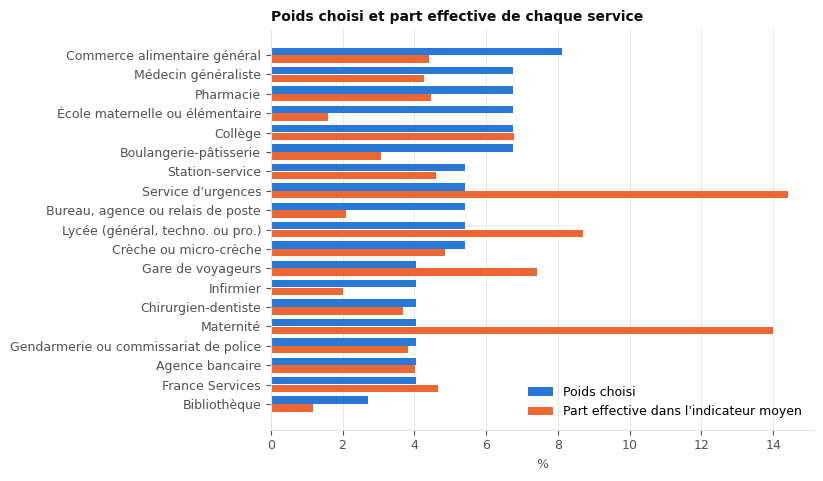

In [12]:
# Poids choisi vs part réelle de chaque service dans l'indicateur moyen
ordre = poids.sort_values("poids").index
y = np.arange(len(ordre))
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(y + 0.2, poids.loc[ordre, "poids"] * 100, 0.38, color=BLEU, label="Poids choisi")
ax.barh(y - 0.2, stats.loc[ordre, "contribution"] * 100, 0.38, color=ORANGE,
        label="Part effective dans l'indicateur moyen")
ax.set_yticks(y, poids.loc[ordre, "libelle"].str.slice(0, 38))
ax.set_xlabel("%")
ax.xaxis.grid(True, color=GRILLE, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Poids choisi et part effective de chaque service")
plt.show()

Nous gardons cette propriété, car elle correspond à la demande : mesurer une **distance**.
Être à 40 km d'une maternité est réellement plus pénalisant qu'être à 3 km d'une boulangerie.
En revanche, il faut la connaître pour interpréter le résultat : l'indicateur reflète beaucoup
l'accès à l'hôpital.

### Deux variantes pour tester la robustesse

- **Poids égaux** ($w_s = 1/19$) : teste l'influence de la grille de notation.
- **Distances normalisées** : chaque distance est divisée par la distance moyenne nationale
  du service, pour neutraliser l'effet d'échelle. L'indicateur devient sans unité
  (1 = commune moyenne) et seuls les poids hiérarchisent les services :

$$\tilde{I}_c = \sum_{s} w_s\,\frac{d_{c,s}}{\bar{d}_s} \qquad \bar{d}_s = \frac{1}{N}\sum_{c} d_{c,s}$$

In [18]:
display(tableau(pd.DataFrame({
    "Corrélation de Spearman avec l'indicateur retenu": [
        "Variante à poids égaux", "Variante à distances normalisées"],
    "Valeur": [fr(rho.loc["indicateur", "indic_poids_egaux"], 3),
               fr(rho.loc["indicateur", "indic_normalise"], 3)],
})))

Corrélation de Spearman avec l'indicateur retenu,Valeur
Variante à poids égaux,"0,998"
Variante à distances normalisées,"0,958"


Les classements restent presque identiques : **les conclusions ne dépendent pas du choix précis des poids**. Cela s'explique : les communes qui manquent d'un service manquent en général de beaucoup d'autres (46 % des communes n'ont aucun ou un seul des 19 services). Les deux variantes sont fournies dans le fichier de résultats (colonnes `indic_poids_egaux` et `indic_normalise`).

## 9. Limites

- **Vol d'oiseau, pas temps de trajet** : sous-estime l'éloignement en montagne et pour les
  îles (Île-de-Sein, Ouessant) où il faut prendre un bateau. Un distancier routier (OSRM,
  Métric) serait plus juste mais beaucoup plus coûteux.
- **Effet frontière** : les équipements situés à l'étranger (Suisse, Espagne, Belgique...) ne
  sont pas comptés ; les communes frontalières sont pénalisées.
- **Présence binaire** : posséder une pharmacie pour 50 000 habitants ou pour 200 donne le même
  0 ; la capacité et les délais d'attente (déserts médicaux) ne sont pas mesurés. De même, une
  grande commune « possède » un service qui peut être à 10 km de certains de ses hameaux.
- **Pondération normative** : la grille E/F/P est un choix raisonné mais subjectif. Les tests
  de robustesse montrent qu'elle modifie peu les classements.
- **Un seul point par commune** : la population n'est pas répartie uniformément ; la mairie
  reste une approximation du lieu de vie des habitants.